```
---
title: Intro Classification + KNN
duration: "1:5"
creator:
    name: Kiefer Katovich + David Yerrington
    city: SF
---
```

<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 15px; height: 80px">

# Intro to Classification + KNN
Week 4 | Lesson 4.01


![](https://snag.gy/RKWYcC.jpg)

### LEARNING OBJECTIVES
*After this lesson, you will be able to:*
- Understand broad applications of classification
- Intuition behind the KNN algorithm
- Bias / Variance tradeoff using hyper-parameters of KNN
- Implementing KNN with sklearn

---

# (5 mins) Discussion:

# 1.  Exactly what is classification and how is it different than regression?
# 2 . What sort of problems do you solve with classification?

# Identify that problem:  Classification or Regression?

![](https://snag.gy/0j5DbL.jpg)




# Identify that problem: Classification or Regression?

![](https://snag.gy/Rk6sEw.jpg)

# Identify that problem: Classification or Regression?

<br>
<center>_Predicting bathrooms on Star Trek starships based on dilithium crystal size and warp capabilities._</center>

![](https://snag.gy/9Nok4x.jpg)

# Identify that problem: Classification or Regression?
<br>

![](https://snag.gy/lS3FNa.jpg)

## Identify that Problem: Classification or Regression

![](http://i.imgur.com/B67Ojpe.gif)

## Classification Intro

![](https://snag.gy/0Jns5x.jpg)

Classifcation methods in machine learning are fundamentally supervised methods where the training data which observations are associated with a (discrete) label designating their class.  Classification is different than regression (with continious values) because we are now predicting classes / labels.  This can be thought of as a discrimination problem, modelling the differences or similarities between groups. 

*Classifcation is supervised because we know the labels of our trained / sampled observations.*





## Common Classification Problems

The realm of classifcation is vast in the machine learning world.  Working with labled data still gives us the opporuntity to measure error.

### Facial Recognition
![](http://3qeqpr26caki16dnhd19sv6by6v.wpengine.netdna-cdn.com/wp-content/uploads/2013/11/face_detection.jpg)

### Recommendation
Some aspects of recommender systems can be solved as classification problems.
![](https://snag.gy/zKcO31.jpg)

### Sentiment Analysis 
![](https://snag.gy/DbX2TL.jpg)

# Common Classification Methods

## K-Nearest Neighbors
![](https://snag.gy/J38wxN.jpg)

## Logistic Regression
![](https://snag.gy/NCnh3b.jpg)

## Naive Bayes
![](https://snag.gy/ZJwmn6.jpg)

## Decision Trees
![](https://snag.gy/cJL5gr.jpg)

## Classfication Evaluation

Classification is assessed much differently than continuious regression.  Generally, we are concerned with if we misidentified anything incorrectly, completely missed the mark, or predicted correctly between our traning and test sets during cross validation.  There are a few different things we usually talk about and look at when it pertains to classification related to these ideas such as **precision**, **recall**, **accuracy**, **F-measures**, **class imbalance**, and our beloved **Reciever Operator Curve**.

Once we get a sense of how our classfication method performs, we have the opporutnity to tune for sensitivity or specificity.

> **Sensitivity and specificity** are statistical measures of the performance of a binary classification test, also known in statistics as classification function:

> **Sensitivity** (also called the true positive rate, the recall, or probability of detection[1] in some fields) measures the proportion of positives that are correctly identified as such (e.g., the percentage of sick people who are correctly identified as having the condition).

> **Specificity** (also called the true negative rate) measures the proportion of negatives that are correctly identified as such (e.g., the percentage of healthy people who are correctly identified as not having the condition).

> [Sensitivity and Specificity](https://en.wikipedia.org/wiki/Sensitivity_and_specificity)


#### Confusion Matrix
![](https://snag.gy/qit9l3.jpg)

**Confusion Matrix - sklearn**
![](https://snag.gy/b6VDIo.jpg)

### ROC Figures
![](https://snag.gy/CBxZbh.jpg)

### sklearn "classification_report()"
```python
>>> from sklearn.metrics import classification_report
>>> y_true = [0, 1, 2, 2, 0]
>>> y_pred = [0, 0, 2, 1, 0]
>>> target_names = ['class 0', 'class 1', 'class 2']
>>> print(classification_report(y_true, y_pred, target_names=target_names))
             precision    recall  f1-score   support

    class 0       0.67      1.00      0.80         2
    class 1       0.00      0.00      0.00         1
    class 2       1.00      0.50      0.67         2

avg / total       0.67      0.60      0.59         5
```

# K Nearest Neighbors classification walkthrough

From here on out we are going to look at how the kNN algorithm classifies malignant vs. benign tumor category in the Wisconsin breast cancer dataset.

---

## kNN

![](https://snag.gy/hatSE6.jpg)

The pseudocode algorithm for kNN is as follows:



```
for unclassified_point in sample:
    for known_point in known_class_points:
        calculate distances (euclidean or other) between known_point and unclassified_point
    for k in range of specified_neighbors_number:
        find k_nearest_points in known_class_points to unclassified_point
    assign class to unclassified_point using "votes" from k_nearest_points
```
> ### Common KNN Distance Functions
> These distance functions can be used with KNN.  Euclidean is the most common choice.
>
> ### Euclidean  
> $\sqrt{\sum\limits_{i=1}^k(x_i - y_i)^2}$
>
> ### Manattan 
> $\sum\limits_{i=1}^k \left| x_i - y_i \right|$
>
> ### Minkowski
> $\left(\sum_{i=1}^n |x_i-y_i|^p\right)^{1/p}$

---

[NOTE: in the case of ties, sklearn's `KNeighborsClassifier()` will just choose the first class using uniform weights! If this is unappealing to you you can change the weights keyword argument to 'distance'.]

<a id='euclidean'></a>
## Euclidean distance

---
KNN typically uses one of two distance metrics: euclidean or manhattan. Other distance metrics are possible, but more rare (sometimes it makes sense to create your own distance function).


Recal the famous Pythagorean Theorem
![Alt text](http://ncalculators.com/images/pythagoras-theorem.gif)

We can apply the theorem to calculate distance between points. This is called Euclidean distance. 

![Alt text](http://rosalind.info/media/Euclidean_distance.png)

### $$\text{Euclidean  distance}=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}$$

There are many different distance metrics, but Euclidean is the most common (and default in sklearn).


## A Basic Example

A basic example first, using a randomly generated dataset having 2 classes.  If we were to predict new points, we need to know where our current observations exist in 2D space.

> _Euclidean distance (and many other distance metrics) can be used in higher dimensional spaces, therefore KNN can with data having more than 2 dimensions._

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_biclusters

import pandas as pd
import seaborn as sns

sns.set(font_scale=1)
sns.set(font_scale=2.5)

%matplotlib inline

In [3]:
## Geneate 2 random clusters, create dataframe

### Predicting a "new" unknown point

Predicting a new point using the **KNN** algorithm, is as follows:

1. Calculate the distance of the new point (labeled: "X")
1. $K$ closest points, vote for the ownership of the new point
1. New point assigned to majority vote class

>  _Let's hold our questions about what happens two classes have the same votes!  We'll get to the edge cases soon!_


In [5]:
# Plot scatter with 2 classes

# Plot our new point


In [6]:
# Plot scatter with 2 classes

# Plot our new point

# Plot distnace lines to all points to new unknown point!

### Calculate the distances from every point to our unknown point "X"

In [7]:
from sklearn.metrics import pairwise_distances

# calculate distances
k = 11

### Select only the "k" closest points
The closest "k" points are considered for voting.  In this case let's select 11, for our "K".

In [8]:
import matplotlib.pyplot as plt

# Plot scatter with 2 classes

# Plot our new point

# Plot distnace lines to all points to new unknown point!


### What does the hyperparameter $K$ do to bias / variance tradeoff in KNN?

/poll "What does the hyperparameter K do to bias?" "higher k = higer variance" "higher k = higher irreducable error" "higher k = higher bias" anonymous

In a thread (after a the majority of votes have been cast), what about variance?

### What about all those edge cases?

Well that's a grand question!

#### What if we have an equal amount of votes per class, to predict a point?
- We can weight the samples that are closer a point to have more value in the voting process.
- Using an odd quantity for $k$ can help avoid classes having the same score towards predicted points.

#### KNN seems pretty simple.  Is it?

If we're considering uniform distance value of distance (no weghted assumptions), with larger datasets, calculating the distances to known vs unknown points becomes very inefficient with larger datasets.  Even with weighted distances, KNN is still not very effecient.  In class we will worry abou this per-se, but in order to scale this algorithm for larger datasets, one of the main problems is efficient sampling of points closest to the unknown point to limit the number of distance calculations required.

## KNN in sklearn

We will load up a multinomial dataset having 3 classes.
- Inspect dataset using a pairplot in multiple dimensions
- Implement KNN in sklearn
- Search range of $K$ for optimal accuracy 

In [9]:
sns.set(font_scale=1)   ## reset font_scale
sns.set(font_scale=1.5) ## update font_scalet to new value

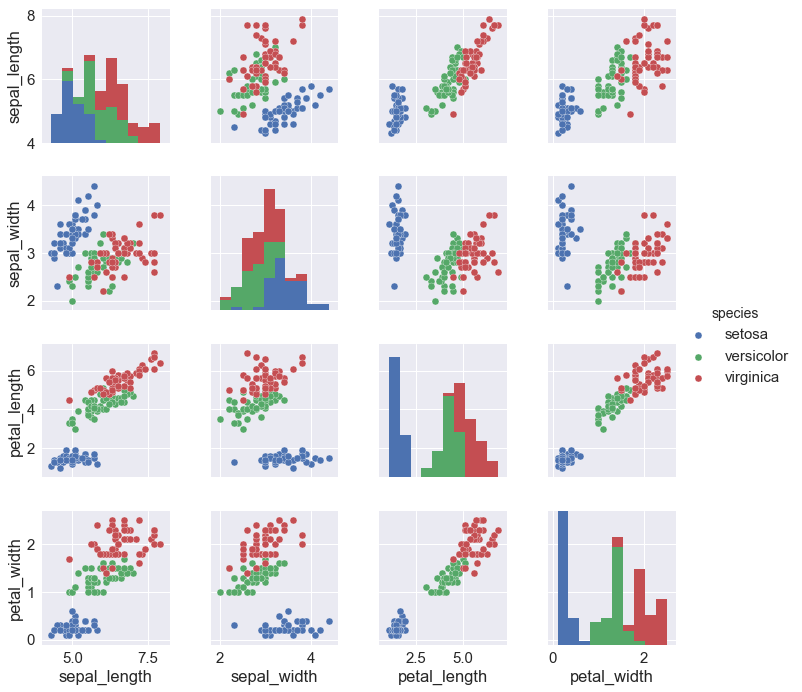

In [10]:
iris = sns.load_dataset("iris")

sns.pairplot(iris, hue="species")

###  Insepct features that differentiate classes the most

**Versicolor and Virginica mixing together**

These are not a problem since when combined with other variables, provide good separation.

- **sepal width** with **sepal width** 
- **sepal_length** with **sepal_width**


Every other variable combination seems to seperate our 3 classes (blue, green, and red) pretty well.  Yes, this is a very perfect example!

>  Evaluating multiple variable combinations with a lot of real-world datasets, will be a bit more tedius.

#### We will use the petal variables to predict the flower species!

Initializing KNN and fitting a model is not so much different than other models we've used so far.

> **n_neightbors** is the hyperparameter $K$!

In [11]:
# Predictors X, and target y for our model
X = iris[['petal_width', 'petal_length']]
y = iris['species']

# Intialize our model

# Score our model


#### Accuracy is fairly high!

We can still see the effect of "k" over a range of potential values.

In [12]:
X = iris[['petal_width', 'petal_length']]
y = iris['species']

scores = []

# Iterate through range for parameter k

### Cross-validation

In [313]:
from sklearn.cross_validation import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3)

# knn = KNeighborsClassifier(n_neighbors=5)
# model = knn.fit(X_train, y_train)
# model.score(X_test, y_test)

0.93333333333333335

### Any problems you can think of using accuracy as a metric?

We may look at a confusion matrix.

In [ ]:
from sklearn.metrics import confusion_matrix

y_hat = model.predict(X_test)

classes = ["Setosa", "Versicolor", "verginica"]
cm = confusion_matrix(y_test, y_hat)
cm = pd.DataFrame(cm, columns=classes)
cm.index = classes

sns.heatmap(cm, annot=True)

### Time Permitting - Explore Bias / Variance with "K" with new data on  your own!

Generally fewer number of neighbors will make your model learn to predict on the specific variance of our data (as a result of variance) and the boundaries / edges of classes will look more jagged but too many neighbors will not capture the general characteristics of your data (smoother edges and less distinction between classes -- less variance -- less distinction between classes). 

- Higher k will decrease variance and increase bias.
- Lower k will increase variance and decrease bias

A good way to choose K is to iterate on a few different models score, but also look at precion / recall / F1 in addition to score for each K to see how it  performs on accuracy, but also the other metrics that relate to each class.  Not only is overall accuracy important to understand, but also the rate of misclassfication / performance per each class.

> <img src="https://snag.gy/26k4Qa.jpg" width="500">
> Mainly, you're looking to find that "sweet spot" between bias and variance.  With a K too high or low, you're going to hit one side or the other of this trade-off.

** Practice **

1. Adapt our previous example that builds a score dataframe, to fit a range of K against this new dataset.
1. Plot results of score over range of $K$.

In [354]:
cancer = pd.read_csv("./datasets/breast_cancer_wisconsin/breast_cancer.csv")

X = cancer[['Mitoses', 'Clump_Thickness']]
y = cancer['Class']

knn = KNeighborsClassifier(n_neighbors=10)
model = knn.fit(X, y)
model.score(X, y)

0.89413447782546496

In [13]:
# Collect the output of model scores from a range of K

scores = []

for k in range(1,91,2):
    knn = KNeighborsClassifier(n_neighbors=k)
    model = knn.fit(X, y)
    
    scores.append((k, model.score(X, y)))
    
    ## Collect scores here
    ## scores.append(??????)

### Put scores into a dataframe
### Plot scores with scores on the y axis, and n_neighbors as the x axis

### Optional - Plot confusion matrix

This will be talked about at great length in our future classfication metrics and evaluation lectures.

In [361]:

## This is here in case you want to use this in the future.
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

## Conclusion

- In classification, a class is the target.

/poll "What is 'K' in K Nearest Neighbors?" "The hyperparameter for controlling variance" "It limits the maximum distance for prediction" "It defines which points can be used for voting for predictions"

What are some problems with using accuracy as the only metric for model optimization?